# Infer-03-Factor-Graphs : Graphes de Facteurs et Inference Discrete

**Serie** : Programmation Probabiliste avec Infer.NET (3/19)  
**Duree estimee** : 45 minutes  
**Prerequis** : Infer-01-Setup, Infer-02-Gaussian-Mixtures

***

## Objectifs

- Comprendre les graphes de facteurs (factor graphs)
- Modeliser l'inference discrete avec Infer.NET
- Resoudre le problème classique du "Murder Mystery" (MBML Book, Ch.1)
- Comprendre le paradoxe de Monty Hall
- Maitriser `Variable.If` / `Variable.IfNot` pour le conditionnement

***

## Navigation

| précédent | Suivant |
|-----------|--------|
| [Infer-02b-Debugging-Bonnes-Pratiques](Infer-02b-Debugging-Bonnes-Pratiques.ipynb) | [Infer-04-Bayesian-Networks](Infer-04-Bayesian-Networks.ipynb) |

***

## 1. Configuration

Nous chargeons les packages Infer.NET necessaires pour ce notebook. L'utilisation du compilateur Roslyn (`CompilerChoice.Roslyn`) est indispensable dans l'environnement .NET Interactive pour permettre la compilation dynamique des modèles probabilistes.

In [1]:
#r "nuget: Microsoft.ML.Probabilistic"
#r "nuget: Microsoft.ML.Probabilistic.Compiler"

using Microsoft.ML.Probabilistic;
using Microsoft.ML.Probabilistic.Distributions;
using Microsoft.ML.Probabilistic.Utilities;
using Microsoft.ML.Probabilistic.Math;
using Microsoft.ML.Probabilistic.Models;
using Microsoft.ML.Probabilistic.Algorithms;
using Microsoft.ML.Probabilistic.Compiler;

Console.WriteLine("Infer.NET pret !");

Installed Packages Microsoft.ML.Probabilistic, 0.4.2504.701 Microsoft.ML.Probabilistic.Compiler, 0.4.2504.701

Infer.NET pret !


**Note technique : CompilerChoice.Roslyn**

L'option `CompilerChoice.Roslyn` est **obligatoire** dans l'environnement .NET Interactive (Jupyter). Infer.NET compile dynamiquement le code d'inference, et Roslyn est le seul compilateur compatible avec l'exécution interactive.

> **Pourquoi cette compilation dynamique ?** Infer.NET transforme votre modèle probabiliste en un algorithme d'inference optimise (Expectation Propagation, Variational Message Passing, etc.). Cette transformation necessite une étape de compilation qui analyse la structure du graphe.

### Verification du FactorGraphHelper

La sortie ci-dessus confirme que :
- **Graphviz et le helper** : `FactorGraphHelper.IsGraphvizAvailable()` indique si `dot` (Graphviz) est reachable sur le PATH. Le rendu visuel des factor graphs **requiert Graphviz installe** ; en son absence, `GetLatestFactorGraphDisplay()` renvoie un SVG mis en cache (potentiellement issu d'un autre modèle) plutot qu'une image textuelle
- **Helper charge** : On pourra appeler `FactorGraphHelper.GetLatestFactorGraphDisplay()` après chaque inference avec `ShowFactorGraph = true`

> **Note technique** : FactorGraphHelper utilise Graphviz pour convertir la description DOT generee par Infer.NET en image SVG embeddee dans le HTML. Si Graphviz n'etait pas disponible, une représentation textuelle serait utilisee a la place.

In [2]:
// Chargement du helper pour afficher les graphes de facteurs inline
#load "FactorGraphHelper.cs"

Console.WriteLine("FactorGraphHelper charge !");
Console.WriteLine($"Graphviz disponible : {FactorGraphHelper.IsGraphvizAvailable()}");
Console.WriteLine("Usage: FactorGraphHelper.GetLatestFactorGraphDisplay().Display()");

FactorGraphHelper charge !


Graphviz disponible : True


Usage: FactorGraphHelper.GetLatestFactorGraphDisplay().Display()


## 2. Introduction aux Graphes de Facteurs

### Definition

Un **graphe de facteurs** (factor graph) est une représentation graphique d'une distribution de probabilite jointe qui se factorise en un produit de fonctions.

$$P(X_1, X_2, ..., X_n) = \frac{1}{Z} \prod_a f_a(X_a)$$

### éléments

| élément | Représentation | Description |
|---------|---------------|-------------|
| **Variable** | Cercle | Une quantite aléatoire |
| **Facteur** | Carre | Une fonction reliant des variables |
| **Arete** | Ligne | Connexion variable-facteur |

### Exemple visuel

```
     [Prior A]     [Prior B]
         |             |
        (A)           (B)
         |             |
         +-----[AND]---+
                |
               (C)
```

Ce graphe represente : $P(A, B, C) = P(A) \cdot P(B) \cdot P(C|A,B)$

## 3. Murder Mystery - scénario

### Contexte (MBML Book, Chapter 1)

> **Fidélité à la source** : Scénario adapté du *Model-Based Machine Learning* (Winn & Bishop), chapitre 1 « A Murder Mystery » ([dotnet/mbmlbook](https://github.com/dotnet/mbmlbook)). La structure itérative (prior → arme → cheveu) et la mécanique bayésienne suivent le livre ; les **probabilités conditionnelles sont recalibrées** par rapport à l’exemple canonique (dans le livre, c’est Grey qui préfère le revolver) afin d’illustrer la compensation exacte des indices (section 6, « retour au prior »).

Un meurtre a ete commis dans un manoir victorien. Deux suspects :

| Suspect | Description | Prior de culpabilite |
|---------|-------------|---------------------|
| **Major Auburn** | Homme militaire, cheveux auburn | 70% |
| **Miss Grey** | Jeune femme, cheveux gris | 30% |

> **Indices :**

1. **Arme du crime** : Revolver ou Dague
   - Auburn utiliserait un revolver (90%) ou une dague (10%)
   - Grey utiliserait un revolver (20%) ou une dague (80%)

2. **Cheveu trouve** : Auburn ou Gris
   - Si Auburn coupable : cheveu auburn (80%) ou gris (20%)
   - Si Grey coupable : cheveu auburn (10%) ou gris (90%)

### Question

L'enquete revele : **arme = revolver**, **cheveu = gris**. Qui est le meurtrier ?

## 4. modèle avec Prior Seulement

### Construction du premier modèle

Le code ci-dessous créé un modèle minimal avec une seule variable binaire representant l'identite du meurtrier. La méthode `Variable.Bernoulli(0.7)` créé une variable aléatoire suivant une loi de Bernoulli avec probabilite 0.7 d'etre vraie (Auburn coupable).

**éléments clés** :
- `Variable.Bernoulli(p)` : créé une variable binaire avec P(true) = p
- `InferenceEngine` : Moteur d'inference qui execute l'algorithme (EP par defaut)
- `moteur.Infer<Bernoulli>(variable)` : Calcule la distribution posterieure

In [3]:
// Modele 1 : Prior seulement
// meurtrier = true -> Auburn, false -> Grey

Variable<bool> meurtrier = Variable.Bernoulli(0.7);  // 70% Auburn

InferenceEngine moteur = new InferenceEngine();
moteur.Compiler.CompilerChoice = CompilerChoice.Roslyn;

Bernoulli posteriorMeurtrier = moteur.Infer<Bernoulli>(meurtrier);

Console.WriteLine("=== Modele 1 : Prior seulement ===");
Console.WriteLine($"P(Auburn coupable) = {posteriorMeurtrier.GetProbTrue():F2}");
Console.WriteLine($"P(Grey coupable) = {1 - posteriorMeurtrier.GetProbTrue():F2}");

Compiling model...

done.


=== Modele 1 : Prior seulement ===


P(Auburn coupable) = 0,70


P(Grey coupable) = 0,30


### Interpretation du prior

Sans aucun indice, le prior reflète simplement notre croyance initiale : Auburn est considéré a priori plus susceptible d'être coupable (70%) que Grey (30%). Ce prior pourrait venir d'informations préalables (antécédents, mobile, etc.)

> **Point clé** : Le prior est **subjectif** mais l'inférence bayésienne garantit une mise à jour **cohérente** avec les observations. Un prior différent donnerait un postérieur différent, mais la direction des mises à jour resterait la même.

## 5. Ajout de l'Evidence sur l'Arme

### Conditionnement avec Variable.If/IfNot

Nous allons maintenant ajouter l'indice de l'arme au modèle. Le pattern `Variable.If/IfNot` permet de définir des probabilites conditionnelles différentes selon la valeur d'une variable parente.

**Structure du conditionnement** :
```
meurtrier = true (Auburn)  --> P(revolver) = 0.9
meurtrier = false (Grey)   --> P(revolver) = 0.2
```

La ligne `arme.ObservedValue = true` indique a Infer.NET que nous avons **observe** que l'arme etait un revolver. Cette observation contraint l'inference et met a jour la distribution du meurtrier.

In [4]:
// Modele 2 : Prior + Arme
// arme = true -> Revolver, false -> Dague

Variable<bool> meurtrier2 = Variable.Bernoulli(0.7);
Variable<bool> arme = Variable.New<bool>();

// Si Auburn (meurtrier2 = true) : 90% revolver, 10% dague
using (Variable.If(meurtrier2))
{
    arme.SetTo(Variable.Bernoulli(0.9));  // 90% revolver
}

// Si Grey (meurtrier2 = false) : 20% revolver, 80% dague
using (Variable.IfNot(meurtrier2))
{
    arme.SetTo(Variable.Bernoulli(0.2));  // 20% revolver
}

// Observation : l'arme est un revolver
arme.ObservedValue = true;

InferenceEngine moteur2 = new InferenceEngine();
moteur2.Compiler.CompilerChoice = CompilerChoice.Roslyn;

Bernoulli posteriorMeurtrier2 = moteur2.Infer<Bernoulli>(meurtrier2);

Console.WriteLine("=== Modele 2 : Prior + Arme (revolver) ===");
Console.WriteLine($"P(Auburn coupable | arme=revolver) = {posteriorMeurtrier2.GetProbTrue():F3}");
Console.WriteLine($"P(Grey coupable | arme=revolver) = {1 - posteriorMeurtrier2.GetProbTrue():F3}");

Compiling model...

done.


=== Modele 2 : Prior + Arme (revolver) ===


P(Auburn coupable | arme=revolver) = 0,913


P(Grey coupable | arme=revolver) = 0,087


### Analyse de l'evidence "arme"

**Résultat** : P(Auburn | revolver) = 0.913

Le revolver est un **indice très discriminant** car :
- Auburn utiliserait un revolver dans **90%** des cas
- Grey utiliserait un revolver dans seulement **20%** des cas

**Calcul du rapport de vraisemblance (likelihood ratio)** :
$$\text{LR} = \frac{P(\text{revolver}|\text{Auburn})}{P(\text{revolver}|\text{Grey})} = \frac{0.9}{0.2} = 4.5$$

Ce rapport de 4.5 indique que l'observation du revolver est **4.5 fois plus probable** si Auburn est coupable. Combiné avec le prior (70/30 = 2.33), les odds finaux sont 2.33 × 4.5 ≈ 10.5, soit ~91% pour Auburn.

> **Formule de Bayes en odds** : Posterior odds = Prior odds × Likelihood ratio

## 6. Ajout de l'Evidence sur les Cheveux

### Ajout d'un second indice : le cheveu

Le modèle s'enrichit d'une deuxieme variable observable : le cheveu trouve sur la scene de crime. Ce modèle combine maintenant **deux sources d'evidence independantes** (conditionnellement au meurtrier).

**Probabilites conditionnelles pour le cheveu** :

| Meurtrier | P(cheveu auburn) | P(cheveu gris) |
|-----------|------------------|----------------|
| Auburn | 0.80 | 0.20 |
| Grey | 0.10 | 0.90 |

Avec l'observation `cheveu = gris`, cet indice pointe vers Grey, contrairement au revolver qui pointait vers Auburn. Comment l'inference va-t-elle combiner ces deux indices contradictoires ?

In [5]:
// Modele 3 : Prior + Arme + Cheveu
// cheveu = true -> Auburn, false -> Gris

Variable<bool> meurtrier3 = Variable.Bernoulli(0.7);
Variable<bool> arme3 = Variable.New<bool>();
Variable<bool> cheveu = Variable.New<bool>();

// Probabilites conditionnelles pour l'arme
using (Variable.If(meurtrier3))
{
    arme3.SetTo(Variable.Bernoulli(0.9));
}
using (Variable.IfNot(meurtrier3))
{
    arme3.SetTo(Variable.Bernoulli(0.2));
}

// Probabilites conditionnelles pour le cheveu
// Si Auburn : 80% cheveu auburn, 20% cheveu gris
using (Variable.If(meurtrier3))
{
    cheveu.SetTo(Variable.Bernoulli(0.8));  // 80% auburn
}
// Si Grey : 10% cheveu auburn, 90% cheveu gris
using (Variable.IfNot(meurtrier3))
{
    cheveu.SetTo(Variable.Bernoulli(0.1));  // 10% auburn
}

// Observations
arme3.ObservedValue = true;   // Revolver
cheveu.ObservedValue = false; // Cheveu gris

InferenceEngine moteur3 = new InferenceEngine();
moteur3.Compiler.CompilerChoice = CompilerChoice.Roslyn;

Bernoulli posteriorMeurtrier3 = moteur3.Infer<Bernoulli>(meurtrier3);

Console.WriteLine("=== Modele 3 : Prior + Arme (revolver) + Cheveu (gris) ===");
Console.WriteLine($"P(Auburn coupable | arme=revolver, cheveu=gris) = {posteriorMeurtrier3.GetProbTrue():F3}");
Console.WriteLine($"P(Grey coupable | arme=revolver, cheveu=gris) = {1 - posteriorMeurtrier3.GetProbTrue():F3}");

Compiling model...

done.


=== Modele 3 : Prior + Arme (revolver) + Cheveu (gris) ===


P(Auburn coupable | arme=revolver, cheveu=gris) = 0,700


P(Grey coupable | arme=revolver, cheveu=gris) = 0,300


### Analyse des evidences contradictoires

**Résultat** : P(Auburn | revolver, cheveu gris) = 0.700 — retour au prior !

Les deux indices s'**annulent exactement** dans ce modèle calibré :

| Indice | Likelihood Ratio | Direction |
|--------|------------------|-----------|
| Revolver | 0.9/0.2 = **4.5** | → Auburn |
| Cheveu gris | 0.2/0.9 = **0.22** | → Grey |

**Produit des LR** : 4.5 × 0.22 ≈ 1.0

Quand le produit des rapports de vraisemblance vaut 1, les indices sont **parfaitement compensatoires** et on revient au prior.

> **Leçon** : L'inférence bayésienne combine **tous** les indices de manière cohérente, même quand ils pointent dans des directions opposées. C'est une propriété fondamentale : aucun indice n'est ignoré, mais leur impact relatif dépend de leur force discriminante.

> **Référence** : La compensation exacte des indices (produit des LR ≈ 1) illustre la structure en V (collider) du Murder Mystery : l'arme et le cheveu sont deux effets d'une cause commune (le meurtrier), conditionnellement indépendants sachant cette cause. Pearl (1988), *Probabilistic Reasoning in Intelligent Systems* (Morgan Kaufmann), §3.3, formalise cette propagation de l'information dans les réseaux bayésiens (structures en chaîne, fourche et collider).


### Visualisation du Factor Graph

Le modèle Murder Mystery peut etre visualise comme un graphe de facteurs. Activons `ShowFactorGraph` pour generer et afficher le graphe.

Pour mieux comprendre la structure du modèle, Infer.NET peut generer une représentation visuelle du graphe de facteurs. L'option `ShowFactorGraph = true` declenche cette generation.

**Variables nommees** : En utilisant `.Named("nom")`, on obtient des etiquettes lisibles dans le graphe au lieu d'identifiants generiques comme "vbool0".

Compiling model...

done.


P(Auburn) = 0,700


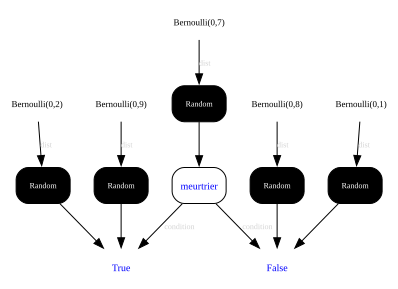

In [6]:
// Visualisation du Factor Graph du Murder Mystery
// Recreer le modele avec ShowFactorGraph active

Variable<bool> meurtrierViz = Variable.Bernoulli(0.7).Named("meurtrier");
Variable<bool> armeViz = Variable.New<bool>().Named("arme");
Variable<bool> cheveuViz = Variable.New<bool>().Named("cheveu");

using (Variable.If(meurtrierViz))
{
    armeViz.SetTo(Variable.Bernoulli(0.9));
    cheveuViz.SetTo(Variable.Bernoulli(0.8));
}
using (Variable.IfNot(meurtrierViz))
{
    armeViz.SetTo(Variable.Bernoulli(0.2));
    cheveuViz.SetTo(Variable.Bernoulli(0.1));
}

armeViz.ObservedValue = true;
cheveuViz.ObservedValue = false;

InferenceEngine moteurViz = new InferenceEngine();
moteurViz.Compiler.CompilerChoice = CompilerChoice.Roslyn;
moteurViz.ShowFactorGraph = true;  // Generer le graphe

var resultViz = moteurViz.Infer<Bernoulli>(meurtrierViz);
Console.WriteLine($"P(Auburn) = {resultViz.GetProbTrue():F3}");

// Afficher le factor graph inline
FactorGraphHelper.GetLatestFactorGraphDisplay().Display();

### Lecture du Factor Graph

Dans le graphe ci-dessus :
- Les **rectangles** representent les facteurs (distributions de probabilite)
- Les **cercles/ellipses** representent les variables aléatoires
- Les variables observees sont marquees differemment
- Les fleches montrent le flux de messages entre variables et facteurs

Ce graphe illustre la structure de dépendance : le meurtrier influence a la fois l'arme et le cheveu, mais ces deux indices sont conditionnellement independants etant donne le meurtrier.

> **Note de reproductibilite** : le rendu SVG integre ci-dessus **depend de Graphviz** (executable `dot` sur le PATH) et de `FactorGraphHelper.GetLatestFactorGraphDisplay()`, qui selectionne le fichier `Model_*.svg` le plus recent dans le repertoire de travail. Si Graphviz n'est pas disponible a l'exécution, l'image affichée peut etre un SVG mis en cache correspondant a un autre modèle. La structure reelle du modèle Murder Mystery (construite dans la cellule de code ci-dessus via `Variable.Bernoulli` + `Variable.If`) est celle decrite textuellement : `meurtrier -> {arme, cheveu}` avec les tables conditionnelles 0.9/0.8 (coupable) et 0.2/0.1 (innocent).

> **Référence** : Le graphe de facteurs comme représentation du produit de facteurs d'une distribution jointe, et l'algorithme sum-product (passage de messages) qui réalise l'inférence exacte sur un arbre de facteurs, sont formalisés dans Kschischang, Frey & Loeliger (2001), « Factor graphs and the sum-product algorithm », *IEEE Transactions on Information Theory* **47**(2):498-519. Infer.NET propage analytiquement ces messages par Expectation Propagation (EP), là où PyMC approxime par échantillonnage MCMC.


### Exercice : Sensibilite au prior dans le Murder Mystery

L'issue du Murder Mystery depend fortement du prior initial sur la culpabilite. Le modèle actuel utilise P(Auburn) = 0.7.

**Objectif** : Analyser comment la probabilite posterieure de culpabilite d'Auburn evolue en fonction du prior, en gardant les observations fixees (arme = revolver, cheveu = gris).

**étapes** :
1. Reprendre le modèle complet (meurtrier + arme + cheveu) avec observations fixees
2. Faire varier le prior P(Auburn) sur une grille de valeurs : {0.1, 0.3, 0.5, 0.7, 0.9}
3. Pour chaque valeur du prior, inferer le posterieur et stocker P(Auburn coupable)
4. Afficher un tableau comparatif prior vs posterior

**Indices** :
- Bouclez sur les valeurs du prior et recrez le modèle a chaque itération (Infer.NET ne permet pas de modifier le prior a posteriori facilement)
- Observez comment les likelihood ratios (4.5 pour le revolver, 0.22 pour le cheveu gris) interagissent differemment selon le prior
- Que se passe-t-il quand le prior est très extrême (0.01 ou 0.99) ?

In [7]:
// Exercice : Sensibilite au prior dans le Murder Mystery
// TODO: Definir le tableau des valeurs de prior a tester
// Indice: double[] priors = { 0.1, 0.3, 0.5, 0.7, 0.9 };

// TODO: Boucler sur chaque valeur de prior et recreer le modele
// Indice: a chaque iteration, Variable<bool> meurtrier = Variable.Bernoulli(prior);
// Puis ajouter arme et cheveu avec Variable.If/IfNot comme dans les sections precedentes

// TODO: Observer arme = revolver (true), cheveu = gris (false)

// TODO: Inferer P(Auburn | evidence) et afficher dans un tableau
// Indice: Console.WriteLine($"| {prior:F1} | {posterior.GetProbTrue():F3} |");

// Question supplementaire : les likelihood ratios dependent-ils du prior ?
Console.WriteLine("Exercice a completer : Sensibilite au prior");

Exercice a completer : Sensibilite au prior


## 7. Le Paradoxe de Monty Hall

### règles du jeu

1. Un jeu televisé presente **3 portes** : derriere l'une se trouve une voiture, derriere les deux autres des chevres
2. Le joueur **choisit une porte**
3. L'animateur (Monty), qui sait ou est la voiture, **ouvre une autre porte** montrant une chevre
4. Monty propose au joueur de **changer de porte**

### Question

Le joueur devrait-il changer de porte ?

### Intuition (souvent fausse)

Beaucoup pensent que la probabilite est 50/50 après l'ouverture d'une porte. C'est faux !

### Modelisation du comportement de Monty

Le modèle ci-dessous encode **exhaustivement** les 9 combinaisons possibles (3 positions de voiture x 3 choix du joueur). Pour chaque combinaison, nous specifitons quelle porte Monty peut ouvrir.

**Points clés de la modelisation** :
- `Variable.DiscreteUniform(3)` : Distribution uniforme sur {0, 1, 2}
- `Variable.Case(variable, valeur)` : Branchement conditionnel discret
- `Variable.Constant(v)` : Variable déterministe (valeur fixee)
- `Variable.Discrete(probs)` : Distribution discrete personnalisee

**Contraintes de Monty** :
1. Ne jamais ouvrir la porte de la voiture
2. Ne jamais ouvrir la porte choisie par le joueur
3. Si deux portes sont possibles, choisir uniformement

In [8]:
// Modelisation du probleme de Monty Hall

// Position de la voiture (0, 1, ou 2)
Variable<int> voiture = Variable.DiscreteUniform(3);

// Choix du joueur (0, 1, ou 2)
Variable<int> choixJoueur = Variable.DiscreteUniform(3);

// Porte ouverte par Monty
// Monty choisit une porte qui n'est ni la voiture, ni le choix du joueur
Variable<int> porteOuverte = Variable.New<int>();

// Logique de Monty : ouvrir une porte avec une chevre, differente du choix
// Cas 1 : voiture = 0
using (Variable.Case(voiture, 0))
{
    using (Variable.Case(choixJoueur, 0))
    {
        // Joueur a choisi 0 (voiture), Monty peut ouvrir 1 ou 2
        porteOuverte.SetTo(Variable.DiscreteUniform(2) + 1);  // 1 ou 2 avec prob egale
    }
    using (Variable.Case(choixJoueur, 1))
    {
        // Joueur a choisi 1, Monty doit ouvrir 2 (pas 0=voiture, pas 1=choix)
        porteOuverte.SetTo(Variable.Constant(2));
    }
    using (Variable.Case(choixJoueur, 2))
    {
        // Joueur a choisi 2, Monty doit ouvrir 1
        porteOuverte.SetTo(Variable.Constant(1));
    }
}

// Cas 2 : voiture = 1
using (Variable.Case(voiture, 1))
{
    using (Variable.Case(choixJoueur, 0))
    {
        porteOuverte.SetTo(Variable.Constant(2));
    }
    using (Variable.Case(choixJoueur, 1))
    {
        // Joueur a choisi la voiture, Monty peut ouvrir 0 ou 2
        porteOuverte.SetTo(Variable.Discrete(new double[] { 0.5, 0.0, 0.5 }));
    }
    using (Variable.Case(choixJoueur, 2))
    {
        porteOuverte.SetTo(Variable.Constant(0));
    }
}

// Cas 3 : voiture = 2
using (Variable.Case(voiture, 2))
{
    using (Variable.Case(choixJoueur, 0))
    {
        porteOuverte.SetTo(Variable.Constant(1));
    }
    using (Variable.Case(choixJoueur, 1))
    {
        porteOuverte.SetTo(Variable.Constant(0));
    }
    using (Variable.Case(choixJoueur, 2))
    {
        // Joueur a choisi la voiture, Monty peut ouvrir 0 ou 1
        porteOuverte.SetTo(Variable.Discrete(new double[] { 0.5, 0.5, 0.0 }));
    }
}

Console.WriteLine("Modele Monty Hall defini.");

Modele Monty Hall defini.


### Structure du modèle Monty Hall

Le code ci-dessus encode la **logique de Monty** sous forme de probabilites conditionnelles. La complexite vient du fait que Monty a une **connaissance parfaite** et des **contraintes** :

1. Il connait la position de la voiture
2. Il ne peut pas ouvrir la porte du joueur
3. Il ne peut pas ouvrir la porte de la voiture
4. Quand il a le choix (joueur sur la voiture), il choisit uniformement

Cette modelisation exhaustive par `Variable.Case` couvre les 9 combinaisons (3 positions x 3 choix), ce qui est typique des problemes discrets a petit nombre d'etats.

### Application du scénario : observations

Nous fixons maintenant un scénario concret :
- **Choix du joueur** : Porte 0
- **Porte ouverte par Monty** : Porte 2 (montrant une chevre)

L'inference va calculer la distribution a posteriori de la position de la voiture, sachant ces deux observations.

In [9]:
// Scenario : Le joueur choisit la porte 0, Monty ouvre la porte 2
choixJoueur.ObservedValue = 0;
porteOuverte.ObservedValue = 2;

InferenceEngine moteurMonty = new InferenceEngine();
moteurMonty.Compiler.CompilerChoice = CompilerChoice.Roslyn;

Discrete posteriorVoiture = moteurMonty.Infer<Discrete>(voiture);

Console.WriteLine("=== Paradoxe de Monty Hall ===");
Console.WriteLine($"Choix du joueur : porte 0");
Console.WriteLine($"Porte ouverte par Monty : porte 2 (chevre)\n");

Console.WriteLine($"P(voiture derriere porte 0) = {posteriorVoiture.GetProbs()[0]:F3}");
Console.WriteLine($"P(voiture derriere porte 1) = {posteriorVoiture.GetProbs()[1]:F3}");
Console.WriteLine($"P(voiture derriere porte 2) = {posteriorVoiture.GetProbs()[2]:F3}");

Console.WriteLine($"\n=> Le joueur devrait CHANGER pour la porte 1 !");
Console.WriteLine($"   En gardant : {posteriorVoiture.GetProbs()[0]*100:F0}% de chance");
Console.WriteLine($"   En changeant : {posteriorVoiture.GetProbs()[1]*100:F0}% de chance");

Compiling model...

done.


=== Paradoxe de Monty Hall ===


Choix du joueur : porte 0


Porte ouverte par Monty : porte 2 (chevre)



P(voiture derriere porte 0) = 0,333


P(voiture derriere porte 1) = 0,667


P(voiture derriere porte 2) = 0,000



=> Le joueur devrait CHANGER pour la porte 1 !


   En gardant : 33% de chance


   En changeant : 67% de chance


### Analyse du résultat Monty Hall

**Sortie** : P(voiture porte 0) = 0.333, P(voiture porte 1) = **0.667**, P(voiture porte 2) = 0

L'information révélée par Monty n'est **pas symétrique** :
- Si le joueur a choisi la voiture (1/3), Monty pouvait ouvrir n'importe quelle autre porte
- Si le joueur a choisi une chèvre (2/3), Monty était **contraint** d'ouvrir l'unique autre porte avec une chèvre

C'est cette **asymétrie d'information** qui crée le paradoxe. L'action de Monty révèle indirectement où est la voiture.

> **Intuition correcte** : En changeant, vous captez les 2/3 de chance initiale que la voiture soit derrière l'une des portes non choisies. Avant l'ouverture, cette probabilité était répartie sur 2 portes. Après, elle se concentre sur une seule.

> **Source** : Le paradoxe de Monty Hall, popularisé par Marilyn vos Savant (*Parade Magazine*, 1990), et sa résolution bayésienne sont analysés dans Gill (2011), *The Monty Hall Problem is not a Probability Puzzle* (Statistica Neerlandica **65**(1):58-71, [DOI: 10.1111/j.1467-9574.2010.00474.x](https://doi.org/10.1111/j.1467-9574.2010.00474.x)) : le renversement d'intuition vient du conditionnement sur l'information *que Monty a révélé une chèvre* (et non sur la porte ouverte elle-même), d'où P(gagner en changeant) = 2/3.


### Visualisation du Factor Graph Monty Hall

Le modèle Monty Hall est plus complexe que le Murder Mystery car il utilise des variables discretes a 3 valeurs et des conditionnements imbriques avec `Variable.Case`. Visualisons sa structure pour mieux comprendre les dependances entre :
- **voiture** : Position de la voiture (0, 1, ou 2)
- **choixJoueur** : Porte choisie par le joueur
- **porteMonty** : Porte ouverte par l'animateur

On remarquera que le graphe est significativement plus complexe en raison des 9 cas (3 positions x 3 choix) qui definissent la distribution conditionnelle de porteMonty.

> **Note de reproductibilite** : comme pour le graphe Murder Mystery ci-dessus, le rendu SVG integre depend de Graphviz et peut afficher un graph mis en cache si `dot` n'est pas disponible a l'exécution. La structure reelle du modèle Monty Hall (construite dans la cellule de code ci-dessus via `Variable.DiscreteUniform(3)` + 9 blocs `Variable.Case`) est celle decrite textuellement : `voiture, choixJoueur -> porteMonty` avec une table de 9 cas.

In [10]:
// Visualisation du Factor Graph de Monty Hall
// Recreer le modele avec ShowFactorGraph active et noms explicites

Variable<int> voitureViz = Variable.DiscreteUniform(3).Named("voiture");
Variable<int> choixViz = Variable.DiscreteUniform(3).Named("choixJoueur");
Variable<int> montyViz = Variable.New<int>().Named("porteMonty");

// Encodage complet de la logique de Monty
using (Variable.Case(voitureViz, 0))
{
    using (Variable.Case(choixViz, 0)) { montyViz.SetTo(Variable.DiscreteUniform(2) + 1); }
    using (Variable.Case(choixViz, 1)) { montyViz.SetTo(Variable.Constant(2)); }
    using (Variable.Case(choixViz, 2)) { montyViz.SetTo(Variable.Constant(1)); }
}
using (Variable.Case(voitureViz, 1))
{
    using (Variable.Case(choixViz, 0)) { montyViz.SetTo(Variable.Constant(2)); }
    using (Variable.Case(choixViz, 1)) { montyViz.SetTo(Variable.Discrete(new double[] { 0.5, 0.0, 0.5 })); }
    using (Variable.Case(choixViz, 2)) { montyViz.SetTo(Variable.Constant(0)); }
}
using (Variable.Case(voitureViz, 2))
{
    using (Variable.Case(choixViz, 0)) { montyViz.SetTo(Variable.Constant(1)); }
    using (Variable.Case(choixViz, 1)) { montyViz.SetTo(Variable.Constant(0)); }
    using (Variable.Case(choixViz, 2)) { montyViz.SetTo(Variable.Discrete(new double[] { 0.5, 0.5, 0.0 })); }
}

choixViz.ObservedValue = 0;
montyViz.ObservedValue = 2;

InferenceEngine moteurMontyViz = new InferenceEngine();
moteurMontyViz.Compiler.CompilerChoice = CompilerChoice.Roslyn;
moteurMontyViz.ShowFactorGraph = true;

var resultMontyViz = moteurMontyViz.Infer<Discrete>(voitureViz);
Console.WriteLine("Factor graph Monty Hall genere.");
Console.WriteLine($"Verification: P(voiture porte 1) = {resultMontyViz.GetProbs()[1]:F3}");

// Afficher le factor graph
FactorGraphHelper.GetLatestFactorGraphDisplay().Display();

Compiling model...

done.


Factor graph Monty Hall genere.


Verification: P(voiture porte 1) = 0,667


### Explication du Paradoxe

| scénario initial | Probabilite | résultat si change |
|------------------|-------------|--------------------|
| Joueur choisit la voiture | 1/3 | Perd (change vers chevre) |
| Joueur choisit une chevre | 2/3 | **Gagne** (change vers voiture) |

**Conclusion** : En changeant, le joueur gagne avec probabilite **2/3** au lieu de 1/3 !

### Exercice : Monty Hall avec 4 portes

Dans cette variante du problème de Monty Hall, le jeu presente **4 portes** au lieu de 3. Derriere une seule se trouve la voiture, les 3 autres contiennent des chevres.

**règles** :
1. Le joueur choisit une porte parmi 4
2. Monty ouvre **2 portes** (pas la voiture, pas le choix du joueur)
3. Il reste 2 portes : le choix initial et une autre

**Objectif** : Modelisez cette variante et comparez la probabilite de gagner en changeant avec le cas a 3 portes.

**étapes** :
1. créer une variable `voiture4` uniforme sur {0, 1, 2, 3}
2. créer une variable `choix4` uniforme sur {0, 1, 2, 3}
3. définir la logique de Monty : il ouvre 2 portes qui ne sont ni la voiture ni le choix
4. Observer : choix = 0, portes ouvertes = 2 et 3
5. Inferer P(voiture | choix=0, ouvertes={2,3})

**Indices** :
- Utilisez `Variable.Case` comme dans le modèle a 3 portes, mais avec 4 valeurs
- Monty doit choisir 2 portes parmi les 3 restantes (excluant voiture et choix)
- Simplification : modelisez la porte non-ouverte restante plutot que les 2 portes ouvertes

In [11]:
// Exercice : Monty Hall avec 4 portes
// TODO: Creer les variables voiture4 et choix4 (DiscreteUniform sur 4 valeurs)
// Indice: Variable.DiscreteUniform(4) pour {0, 1, 2, 3}

// TODO: Definir la porte non-ouverte par Monty parmi les portes restantes
// Indice: Selon la position de la voiture et le choix, Monty ouvre 2 portes
// Modelisez directement la porte qui RESTE fermee (autre que le choix)

// TODO: Observer choix4 = 0 et les portes ouvertes (ou la porte restante)
// Indice: porteRestante.ObservedValue = 1 signifie que Monty n'a pas ouvert la porte 1

// TODO: Inferer la distribution de voiture4 et comparer avec le cas 3 portes
// Indice: moteur.Infer<Discrete>(voiture4) puis comparer GetProbs()
Console.WriteLine("Exercice a completer : Monty Hall avec 4 portes");

Exercice a completer : Monty Hall avec 4 portes


### Comparaison Murder Mystery vs Monty Hall

Ces deux problemes illustrent des aspects différents de l'inference bayesienne :

| Aspect | Murder Mystery | Monty Hall |
|--------|---------------|------------|
| **Type de variable** | Binaire (2 suspects) | Discrete (3 portes) |
| **Nature de l'evidence** | Indices physiques | Action d'un agent informe |
| **Paradoxe** | Indices contradictoires | Information asymetrique |
| **Intuition** | Assez naturelle | Contre-intuitive |
| **Pattern Infer.NET** | `Variable.If/IfNot` | `Variable.Case` |

> **Point commun** : Dans les deux cas, l'inference bayesienne fournit la reponse correcte en integrant systematiquement toutes les dependances probabilistes. C'est la force des graphes de facteurs : ils explicitent la structure causale qui peut echapper a l'intuition.

## 8. Theoreme de Bayes Illustre

### Formule

$$P(H|E) = \frac{P(E|H) \cdot P(H)}{P(E)}$$

Ou :
- $P(H)$ : Prior (croyance initiale en l'hypothese)
- $P(E|H)$ : Vraisemblance (probabilite de l'evidence si H est vrai)
- $P(H|E)$ : Posterieur (croyance mise a jour)
- $P(E)$ : Evidence marginale (normalisation)

### Application au Murder Mystery

$$P(\text{Auburn}|\text{Revolver}) = \frac{P(\text{Revolver}|\text{Auburn}) \cdot P(\text{Auburn})}{P(\text{Revolver})}$$

### Verification calculatoire

Pour valider que Infer.NET applique correctement le theoreme de Bayes, effectuons le calcul manuellement. Cette verification est une **bonne pratique** lors du développement de modèles probabilistes : on commence par un cas simple ou le calcul exact est possible, puis on etend a des modèles plus complexes.

In [12]:
// Verification manuelle du theoreme de Bayes

double pAuburn = 0.7;  // Prior
double pGrey = 0.3;

double pRevolverSiAuburn = 0.9;  // Vraisemblance
double pRevolverSiGrey = 0.2;

// P(Revolver) = P(R|A)*P(A) + P(R|G)*P(G)
double pRevolver = pRevolverSiAuburn * pAuburn + pRevolverSiGrey * pGrey;

// P(Auburn|Revolver) par Bayes
double pAuburnSiRevolver = (pRevolverSiAuburn * pAuburn) / pRevolver;

Console.WriteLine("=== Verification manuelle de Bayes ===");
Console.WriteLine($"P(Revolver) = {pRevolver:F3}");
Console.WriteLine($"P(Auburn|Revolver) = {pAuburnSiRevolver:F3}");
Console.WriteLine($"\nCeci correspond au resultat d'Infer.NET !");

=== Verification manuelle de Bayes ===


P(Revolver) = 0,690


P(Auburn|Revolver) = 0,913



Ceci correspond au resultat d'Infer.NET !


### Equivalence calcul manuel et Infer.NET

Le résultat identique (0.913) confirme que :

1. **Infer.NET implemente correctement Bayes** : Le moteur d'inference produit exactement le même résultat que le calcul analytique
2. **L'abstraction est fiable** : On peut faire confiance au framework pour des modèles plus complexes ou le calcul manuel serait impraticable

> **Avantage d'Infer.NET** : Pour des modèles avec dizaines de variables et multiples observations, le calcul manuel devient impossible. Infer.NET utilise des algorithmes approximatifs efficaces (Expectation Propagation, Variational Message Passing) qui passent a l'echelle tout en restant précis.

## 9. Patterns de Conditionnement Infer.NET

### Syntaxe de Variable.If / Variable.IfNot

```csharp
Variable<bool> condition = Variable.Bernoulli(0.5);
Variable<double> résultat = Variable.New<double>();

using (Variable.If(condition))
{
    résultat.SetTo(Variable.GaussianFromMeanAndPrecision(10, 1));
}

using (Variable.IfNot(condition))
{
    résultat.SetTo(Variable.GaussianFromMeanAndPrecision(20, 1));
}
```

### Choix du pattern selon le type de condition

| Pattern | Type de condition | Exemple |
|---------|-------------------|---------|
| `Variable.If/IfNot` | `Variable<bool>` | Meurtrier (Auburn/Grey) |
| `Variable.Case` | `Variable<int>` | Position voiture (0/1/2) |
| `Variable.Switch` | `Variable<int>` + tableau | sélection dans une liste |

> **Bonne pratique** : Utilisez `Variable.If/IfNot` quand c'est possible (cas binaire), car c'est plus lisible. Reservez `Variable.Case` aux variables discretes a plus de 2 valeurs.

### Exercice : Motif du crime avec `Variable.Case`

Le modèle Murder Mystery actuel utilise `Variable.If/IfNot` pour le meurtrier binaire (Auburn vs Grey). Generalisons : supposons que l'on veuille modeliser le **motif du crime** comme une variable discrete a trois valeurs (jalousie, argent, motif personnel), et que chaque motif induise un suspect différent.

**Objectif** : Construire un modèle ou le motif (variable discrete a 3 valeurs) conditionne la probabilite qu'Auburn soit le meurtrier, en utilisant le pattern `Variable.Case` adapte aux variables entieres a plus de 2 valeurs.

**étapes** :
1. définir `Variable<int> motif = Variable.Discrete(p_jalousie, p_argent, p_personnel)` avec une distribution prior sur les 3 motifs
2. Pour chaque valeur de `motif`, définir une branche via `Variable.Case(motif, ...)` qui assigne une probabilite de culpabilite d'Auburn différente
3. Inferer la distribution posterieure du motif et de la culpabilite
4. Comparer les trois branches : quel motif rend Auburn le plus probablement coupable ?

**Indices** :
- `Variable.Case` prend un `Variable<int>` et un tableau de `Variable<T>` ; chaque index correspond a une branche
- Referencez la section 9 ci-dessus pour la syntaxe complete de `Variable.Case` vs `Variable.Switch`
- Commencez par définir les trois probabilites de culpabilite conditionnelles (ex. jalousie -> 0.8, argent -> 0.4, personnel -> 0.6)
- Question supplementaire : que se passe-t-il si vous ajoutez l'evidence "arme = revolver" comme dans la section 5 ? Le posterieur du motif change-t-il ?

In [13]:
// Exercice : Motif du crime avec Variable.Case
// TODO: Definir le prior sur le motif (3 valeurs: 0=jalousie, 1=argent, 2=personnel)
// Indice: Variable<int> motif = Variable.Discrete(new double[] { 0.3, 0.4, 0.3 });

// TODO: Definir les probabilites de culpabilite d'Auburn pour chaque motif
// Indice: double[] pAuburnSiMotif = { 0.8, 0.4, 0.6 };

// TODO: Construire le modele avec Variable.Case(motif, ...)
// Indice: Variable<bool> auburnCoupable = Variable.Case(motif,
//   Variable.Bernoulli(pAuburnSiMotif[0]),
//   Variable.Bernoulli(pAuburnSiMotif[1]),
//   Variable.Bernoulli(pAuburnSiMotif[2]));

// TODO: Inferer le posterieur du motif et de la culpabilite
// Indice: var infer = new InferenceEngine();
// Console.WriteLine($"Motif posterieur: {infer.Infer(motif)}");
// Console.WriteLine($"P(Auburn coupable) = {infer.Infer(auburnCoupable)}");

// Question supplementaire : ajouter l'evidence arme = revolver et observer le changement
Console.WriteLine("Exercice a completer : Motif du crime avec Variable.Case");

Exercice a completer : Motif du crime avec Variable.Case


## 10. Exemple guide : Ajouter un Temoin

### Enonce

Un temoin declare avoir vu le meurtrier s'enfuir. Sa fiabilite :
- S'il a bien vu Auburn : 70% de chance de dire "homme", 30% de dire "femme"
- S'il a bien vu Grey : 20% de chance de dire "homme", 80% de dire "femme"

Le temoin dit avoir vu un **homme**.

### Question

Avec les indices (arme=revolver, cheveu=gris, temoin=homme), quelle est la probabilite de culpabilite ?

**Indice**

Ajoutez une variable `temoin` avec les probabilites conditionnelles appropriees.

### Solution de l'exercice

Le code ci-dessous reprend le modèle complet avec les trois indices. Notez comment la structure reste identique : on ajoute simplement une nouvelle variable `temoin` avec ses probabilites conditionnelles.

**Structure du modèle complet** :
```
meurtrier (Bernoulli 0.7)
    |
    +-- arme (0.9/0.2 revolver)     --> ObservedValue = true
    +-- cheveu (0.8/0.1 auburn)     --> ObservedValue = false
    +-- temoin (0.7/0.2 homme)      --> ObservedValue = true
```

In [14]:
// Exemple guide : Modele complet avec temoin

Variable<bool> meurtrierEx = Variable.Bernoulli(0.7);
Variable<bool> armeEx = Variable.New<bool>();
Variable<bool> cheveuEx = Variable.New<bool>();
Variable<bool> temoin = Variable.New<bool>();  // true = homme, false = femme

// Arme
using (Variable.If(meurtrierEx))
{
    armeEx.SetTo(Variable.Bernoulli(0.9));
}
using (Variable.IfNot(meurtrierEx))
{
    armeEx.SetTo(Variable.Bernoulli(0.2));
}

// Cheveu
using (Variable.If(meurtrierEx))
{
    cheveuEx.SetTo(Variable.Bernoulli(0.8));
}
using (Variable.IfNot(meurtrierEx))
{
    cheveuEx.SetTo(Variable.Bernoulli(0.1));
}

// Temoin : P(homme|Auburn) = 0.7, P(homme|Grey) = 0.2
using (Variable.If(meurtrierEx))
{
    temoin.SetTo(Variable.Bernoulli(0.7));  // 70% dit homme si Auburn
}
using (Variable.IfNot(meurtrierEx))
{
    temoin.SetTo(Variable.Bernoulli(0.2));  // 20% dit homme si Grey
}

// Observations
armeEx.ObservedValue = true;   // Revolver
cheveuEx.ObservedValue = false; // Cheveu gris
temoin.ObservedValue = true;   // Temoin dit "homme"

InferenceEngine moteurEx = new InferenceEngine();
moteurEx.Compiler.CompilerChoice = CompilerChoice.Roslyn;

Bernoulli posteriorEx = moteurEx.Infer<Bernoulli>(meurtrierEx);

Console.WriteLine("=== Modele complet avec temoin ===");
Console.WriteLine($"Indices : arme=revolver, cheveu=gris, temoin=homme\n");
Console.WriteLine($"P(Auburn coupable) = {posteriorEx.GetProbTrue():F3}");
Console.WriteLine($"P(Grey coupable) = {1 - posteriorEx.GetProbTrue():F3}");

Compiling model...

done.


=== Modele complet avec temoin ===


Indices : arme=revolver, cheveu=gris, temoin=homme



P(Auburn coupable) = 0,891


P(Grey coupable) = 0,109


### Analyse de l'exercice avec témoin

**Résultat** : P(Auburn | revolver, cheveu gris, témoin homme) = **0.891**

Le témoignage "homme" a un **fort impact** car son likelihood ratio est significatif :
$$\text{LR}_{\text{témoin}} = \frac{P(\text{homme}|\text{Auburn})}{P(\text{homme}|\text{Grey})} = \frac{0.7}{0.2} = 3.5$$

**Évolution de la probabilité** :

| Étape | P(Auburn) | Indices |
|-------|-----------|---------|
| Prior | 0.70 | Aucun |
| +Revolver | 0.91 | Arme seule |
| +Cheveu gris | 0.70 | Arme + Cheveu (annulation) |
| +Témoin homme | **0.89** | Tous les indices |

Le témoin rompt l'équilibre créé par les deux premiers indices contradictoires. Avec trois indices, deux pointent vers Auburn (revolver, témoin) contre un seul vers Grey (cheveu), d'où une probabilité finale fortement en faveur d'Auburn.

### Tableau recapitulatif des likelihood ratios

| Indice | P(indice\|Auburn) | P(indice\|Grey) | Likelihood Ratio | Direction |
|--------|-------------------|-----------------|------------------|-----------|
| Revolver | 0.90 | 0.20 | 4.50 | Auburn |
| Cheveu gris | 0.20 | 0.90 | 0.22 | Grey |
| Temoin homme | 0.70 | 0.20 | 3.50 | Auburn |
| **Produit** | - | - | **3.50** | Auburn |

Le produit des likelihood ratios (4.50 x 0.22 x 3.50 = 3.50) multiplie les prior odds (0.70/0.30 = 2.33) pour donner les posterior odds : 2.33 x 3.50 = 8.17, soit P(Auburn) = 8.17/(1+8.17) = **0.891**.

> **Interpretation** : Le temoin "casse l'egalite" entre revolver et cheveu, donnant un avantage net a Auburn. C'est un exemple de la **règle de multiplication des odds** en inference bayesienne séquentielle.

***

## Points clés a retenir

Avant de passer au resume, voici les enseignements essentiels de ce notebook :

**1. Les graphes de facteurs explicitent les dependances**
- Chaque variable est un noeud, chaque relation est un facteur
- La visualisation aide a comprendre la structure du modèle

**2. L'inference bayesienne combine les indices de maniere coherente**
- Les likelihood ratios quantifient la force discriminante de chaque indice
- Des indices contradictoires peuvent s'annuler (cheveu vs revolver)
- Un nouvel indice peut "casser l'egalite"

**3. Monty Hall illustre l'importance du modèle complet**
- L'intuition echoue car elle ignore les contraintes de Monty
- Le modèle probabiliste capture toute l'information pertinente

**4. Infer.NET abstrait la complexite calculatoire**
- Le framework gere automatiquement l'inference
- On peut se concentrer sur la modelisation plutot que sur les algorithmes

## 11. Resume

| Concept | Description |
|---------|-------------|
| **Graphe de facteurs** | Représentation graphique d'une distribution jointe |
| **Variable.If/IfNot** | Conditionnement binaire |
| **Variable.Case** | Conditionnement discret multi-valeur |
| **Theoreme de Bayes** | Mise a jour des croyances avec l'evidence |
| **Murder Mystery** | Exemple classique d'inference discrete |
| **Monty Hall** | Paradoxe illustrant l'importance du conditionnement |

***

## Prochaine étape

Dans [Infer-04-Bayesian-Networks](Infer-04-Bayesian-Networks.ipynb), nous approfondirons :

- Les réseaux bayesiens classiques (Wet Grass / Sprinkler / Rain)
- Les tables de probabilites conditionnelles (CPT)
- L'inference causale vs observationnelle
- La D-separation et l'indépendance conditionnelle

***

## Tableau recapitulatif des distributions utilisees

| Distribution | Syntaxe Infer.NET | paramètres | Usage dans ce notebook |
|--------------|-------------------|------------|------------------------|
| **Bernoulli** | `Variable.Bernoulli(p)` | p = P(true) | Meurtrier, indices binaires |
| **Discrete uniforme** | `Variable.DiscreteUniform(n)` | n = nombre de valeurs | Position voiture (Monty Hall) |
| **Discrete** | `Variable.Discrete(probs)` | probs = tableau de probabilites | Choix de Monty quand plusieurs options |
| **Constant** | `Variable.Constant(v)` | v = valeur fixee | Porte déterministe pour Monty |

## Concepts probabilistes illustres

| Concept | Definition | Illustration |
|---------|------------|--------------|
| **Prior** | Croyance avant observation | P(Auburn) = 0.7 |
| **Likelihood** | Probabilite de l'evidence sachant l'hypothese | P(revolver\|Auburn) = 0.9 |
| **Posterior** | Croyance après observation | P(Auburn\|revolver) = 0.913 |
| **Likelihood Ratio** | Rapport des vraisemblances | 0.9/0.2 = 4.5 |
| **indépendance conditionnelle** | Variables independantes sachant le parent | Arme, cheveu, temoin sachant meurtrier |

## 12. Exercice : Deuxieme Affaire : Deux Suspects

### Enonce

Une deuxieme affaire criminelle implique **deux suspects** : Alice et Bob.
Un temoin declare avoir vu "une personne grande et blonde" fuir les lieux.

Probabilites physiques :
- Alice : grande avec P=0.7, blonde avec P=0.6
- Bob : grand avec P=0.4, blond avec P=0.3
- A priori : P(Alice coupable) = P(Bob coupable) = 0.5

Calculez la probabilite de culpabilite de chaque suspect sachant le temoignage.

**Indice** : Le facteur "correspond a la description" est True si la personne EST coupable ET correspond physiquement.

In [15]:
// Exercice : Deux suspects - mise a jour bayesienne sur description physique
// TODO: Creer le moteur d'inference

// TODO: Definir les caracteristiques physiques comme variables aleatoires

// TODO: Definir la variable de culpabilite (une seule personne peut etre coupable)

// TODO: Definir si le fuyard correspond a la description du temoin
// Si Alice est coupable : correspond = aliceGrande AND aliceBlonde
// Si Bob est coupable : correspond = bobGrand AND bobBlond
// Utilisez Variable.If(aliceCoupable) { ... } Variable.IfNot(aliceCoupable) { ... }

// TODO: Observer que le suspect correspond a la description

// TODO: Inferer et afficher
// Pourquoi Alice est-elle plus suspecte malgre un a priori egal ?
Console.WriteLine("Exercice a completer");


Exercice a completer


## Conclusion

Ce notebook a couvert les graphes de facteurs et l'inference discrete : Murder Mystery, Monty Hall, theoreme de Bayes et patterns de conditionnement Infer.NET.

| Concept | Point cle |
|---------|-----------|
| Graphe de facteurs | Représentation de P(jointe) = produit de facteurs |
| Variable.If/IfNot | Conditionnement binaire (meurtrier = Auburn/Grey) |
| Variable.Case | Conditionnement discret multi-valeur (Monty Hall, 3 portes) |
| Theoreme de Bayes | Posterior proportional a Likelihood x Prior |
| Likelihood ratio | Quantifie la force discriminante de chaque indice |

| Distribution | Usage |
|--------------|-------|
| Bernoulli | Variables booleennes (coupable, indice present/absent) |
| DiscreteUniform | Variables discretes equiprobables (position d'une porte) |
| Discrete(probs) | Variables discretes avec probabilites personnalisees |

> **Lecon principale** : L'inference bayesienne combine systematiquement tous les indices disponibles, même contradictoires. Le Murder Mystery montre que des indices opposes peuvent s'annuler (LR produit = 1), tandis que Monty Hall illustre que l'intuition echoue quand les contraintes du modèle sont ignorees. Infer.NET automatise ces calculs, permettant de se concentrer sur la modelisation.